In [1]:
import nltk
import pandas as pd

from nltk.sentiment import SentimentIntensityAnalyzer

In [2]:
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\TARUSH\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [3]:
feedback = [
    "I really enjoy learning Python.",
    "The teacher explains everything clearly.",
    "I love studying artificial intelligence.",
    "This course is very helpful.",
    "I am happy with my academic progress.",
    "The lessons are excellent.",

    "I hate studying mathematics.",
    "I cannot understand programming.",
    "This subject is extremely difficult.",
    "I am disappointed with my performance.",
    "The lessons are confusing.",
    "I am struggling with my studies.",

    "Today's class was about machine learning.",
    "I attended the lecture today.",
    "The examination is scheduled for Monday.",
    "We studied neural networks today.",
    "The assignment contains five questions.",
    "Our next class is tomorrow."
]

df = pd.DataFrame({
    "feedback": feedback
})

df

,feedback
0,I really enjoy learning Python.
1,The teacher explains everything clearly.
2,I love studying artificial intelligence.
3,This course is very helpful.
4,I am happy with my academic progress.
5,The lessons are excellent.
6,I hate studying mathematics.
7,I cannot understand programming.
8,This subject is extremely difficult.
9,I am disappointed with my performance.


In [4]:
sia = SentimentIntensityAnalyzer()

In [5]:
df["sentiment_scores"] = df["feedback"].apply(
    lambda text: sia.polarity_scores(text)
)

df

,feedback,sentiment_scores
0,I really enjoy learning Python.,"{'neg': 0.0, 'neu': 0.462, 'pos': 0.538, 'comp..."
1,The teacher explains everything clearly.,"{'neg': 0.0, 'neu': 0.597, 'pos': 0.403, 'comp..."
2,I love studying artificial intelligence.,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp..."
3,This course is very helpful.,"{'neg': 0.0, 'neu': 0.564, 'pos': 0.436, 'comp..."
4,I am happy with my academic progress.,"{'neg': 0.0, 'neu': 0.381, 'pos': 0.619, 'comp..."
5,The lessons are excellent.,"{'neg': 0.0, 'neu': 0.448, 'pos': 0.552, 'comp..."
6,I hate studying mathematics.,"{'neg': 0.649, 'neu': 0.351, 'pos': 0.0, 'comp..."
7,I cannot understand programming.,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound..."
8,This subject is extremely difficult.,"{'neg': 0.411, 'neu': 0.589, 'pos': 0.0, 'comp..."
9,I am disappointed with my performance.,"{'neg': 0.437, 'neu': 0.563, 'pos': 0.0, 'comp..."


In [6]:
df["compound"] = df["sentiment_scores"].apply(
    lambda score: score["compound"]
)

df[["feedback", "compound"]]

,feedback,compound
0,I really enjoy learning Python.,0.5413
1,The teacher explains everything clearly.,0.4019
2,I love studying artificial intelligence.,0.8074
3,This course is very helpful.,0.4754
4,I am happy with my academic progress.,0.7579
5,The lessons are excellent.,0.5719
6,I hate studying mathematics.,-0.5719
7,I cannot understand programming.,0.0000
8,This subject is extremely difficult.,-0.4201
9,I am disappointed with my performance.,-0.4767


In [7]:
def classify_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["sentiment"] = df["compound"].apply(classify_sentiment)

df[["feedback", "compound", "sentiment"]]

,feedback,compound,sentiment
0,I really enjoy learning Python.,0.5413,Positive
1,The teacher explains everything clearly.,0.4019,Positive
2,I love studying artificial intelligence.,0.8074,Positive
3,This course is very helpful.,0.4754,Positive
4,I am happy with my academic progress.,0.7579,Positive
5,The lessons are excellent.,0.5719,Positive
6,I hate studying mathematics.,-0.5719,Negative
7,I cannot understand programming.,0.0000,Neutral
8,This subject is extremely difficult.,-0.4201,Negative
9,I am disappointed with my performance.,-0.4767,Negative


In [8]:
sentiment_counts = df["sentiment"].value_counts()

print(sentiment_counts)

sentiment
Neutral     7
Positive    6
Negative    5
Name: count, dtype: int64


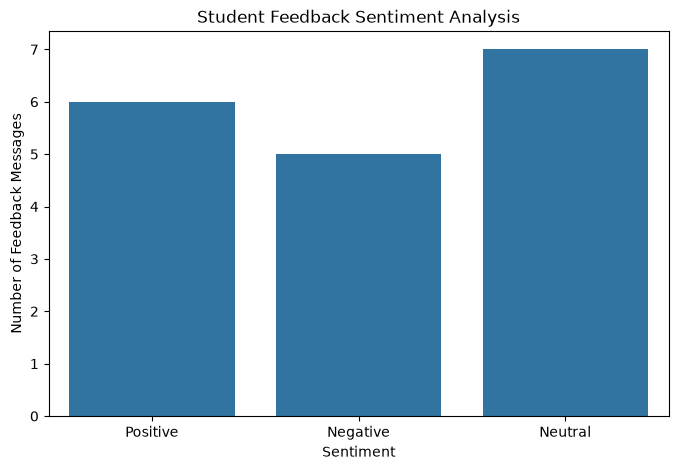

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Student Feedback Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedback Messages")

plt.show()